In [2]:
import xarray as xr 
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

In [3]:
carpeta_de_trabajo = Path.home() / "Desktop" / "Temas selectos Python"
datos = xr.open_dataset(carpeta_de_trabajo / "datos.nc")

C:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xarray\backends\plugins.py:109: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [4]:
print(datos)

# 1. DESCRIBAN EL ARCHIVO

# a) crs: es como la malla, y elevation: Elevation relative to sea level
# b) Dimensiones: ('lat', 'lon'), (1440, 1920)... tamaño-> 2764800
# c) Lat: 18.0->24.0, Long:-93.0->-85.0
# d) metros


<xarray.Dataset> Size: 11MB
Dimensions:    (lat: 1440, lon: 1920)
Coordinates:
  * lat        (lat) float64 12kB 18.0 18.01 18.01 18.01 ... 23.99 23.99 24.0
  * lon        (lon) float64 15kB -93.0 -92.99 -92.99 ... -85.01 -85.01 -85.0
Data variables:
    crs        |S1 1B ...
    elevation  (lat, lon) float32 11MB ...
Attributes: (12/37)
    comment:                         The data in the GEBCO_2026 Grid should n...
    Conventions:                     CF-1.6, ACDD-1.3
    creator_email:                   gdacc@seabed2030.org
    creator_name:                    GEBCO through the Nippon Foundation-GEBC...
    creator_type:                    International organisation
    creator_url:                     https://www.gebco.net
    ...                              ...
    project:                         Nippon Foundation - GEBCO Seabed2030 Pro...
    references:                      DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    source:                          The GEBCO_2026 Grid is 

In [5]:
print(datos['elevation'].attrs)

{'long_name': 'Elevation relative to sea level', 'grid_mapping': 'crs', 'sdn_parameter_name': 'Sea floor height (above mean sea level) {bathymetric height}', 'sdn_parameter_urn': 'SDN:P01::BATHHGHT', 'sdn_uom_name': 'Metres', 'sdn_uom_urn': 'SDN:P06::ULAA', 'standard_name': 'height_above_mean_sea_level', 'units': 'm'}


In [6]:
datos['elevation'].head()

<xarray.DataArray 'elevation' (lat: 5, lon: 5)> Size: 100B
[25 values with dtype=float32]
Coordinates:
  * lat      (lat) float64 40B 18.0 18.01 18.01 18.01 18.02
  * lon      (lon) float64 40B -93.0 -92.99 -92.99 -92.99 -92.98
Attributes:
    long_name:           Elevation relative to sea level
    grid_mapping:        crs
    sdn_parameter_name:  Sea floor height (above mean sea level) {bathymetric...
    sdn_parameter_urn:   SDN:P01::BATHHGHT
    sdn_uom_name:        Metres
    sdn_uom_urn:         SDN:P06::ULAA
    standard_name:       height_above_mean_sea_level
    units:               m

In [7]:
var = datos['elevation']
print(var.dims)
print(var.shape)
print(var.size)

('lat', 'lon')
(1440, 1920)
2764800


In [8]:
var.min() # e) min: -4889

<xarray.DataArray 'elevation' ()> Size: 4B
array(-4889., dtype=float32)
Attributes:
    long_name:           Elevation relative to sea level
    grid_mapping:        crs
    sdn_parameter_name:  Sea floor height (above mean sea level) {bathymetric...
    sdn_parameter_urn:   SDN:P01::BATHHGHT
    sdn_uom_name:        Metres
    sdn_uom_urn:         SDN:P06::ULAA
    standard_name:       height_above_mean_sea_level
    units:               m

In [9]:
var.max() # e) max: 354

#solo es por el nivel del mar, debe significar que hay una fosa o algo asi en alfo muyu negativo, y en lo positivo tal vez una elevación por falla, o quien sabe. 

<xarray.DataArray 'elevation' ()> Size: 4B
array(354., dtype=float32)
Attributes:
    long_name:           Elevation relative to sea level
    grid_mapping:        crs
    sdn_parameter_name:  Sea floor height (above mean sea level) {bathymetric...
    sdn_parameter_urn:   SDN:P01::BATHHGHT
    sdn_uom_name:        Metres
    sdn_uom_urn:         SDN:P06::ULAA
    standard_name:       height_above_mean_sea_level
    units:               m

In [10]:
# f) 


latitudes = var['lat'].values  # o 'latitude'
longitudes = var['lon'].values  # o 'longitude'

print(latitudes)
print(longitudes)

grados= latitudes[1]-latitudes[0]
print(grados)

#0.25°=28km
resolucion= grados*27000/0.25
print(f"resolucion:{resolucion} m")

[18.00208333 18.00625    18.01041667 ... 23.98958333 23.99375
 23.99791667]
[-92.99791667 -92.99375    -92.98958333 ... -85.01041667 -85.00625
 -85.00208333]
0.00416666666666643
resolucion:449.9999999999744 m


In [13]:
####################################### 2. TRES PUNTOS ##########################################

###  a)  ######################

# BANCO DE CAMPECHE

punto_cercano_Camp = datos.sel(lat=22.0, lon=-90.5, method='nearest')
elev_Camp = punto_cercano_Camp['elevation'].values
print(punto_cercano_Camp["lat"].values)
print(punto_cercano_Camp["lon"].values)
print(elev_Camp)

# BANCO DE COZUMEL
punto_cercano_Coz = datos.sel(lat=20.45, lon=-87.5, method='nearest')
elev_Coz = punto_cercano_Coz['elevation'].values
print(punto_cercano_Coz["lat"].values)
print(punto_cercano_Coz["lon"].values)
print(elev_Coz)


#BANCO DE YUCATÁN
punto_cercano_Yuc = datos.sel(lat=21.8, lon=-85.8, method='nearest')
elev_Yuc = punto_cercano_Yuc['elevation'].values
print(punto_cercano_Yuc["lat"].values)
print(punto_cercano_Yuc["lon"].values)
print(elev_Yuc)

### b) El más profundo es Yucatán con -2010 metros bajo el nivel del mar
### c) Fueron las coordenas mas cercanas a un punto y por eso no son iguales s las que le dimos.

21.99791666666667
-90.49791666666667
-31.0
20.447916666666668
-87.49791666666667
19.0
21.79791666666667
-85.79791666666667
-2010.0


In [15]:
####################################### 3. EL BANCO DE CAMPECHE ############################################ 
region = datos['elevation'].sel(lat=slice(21.8, 23.5), lon=slice(-90, -87.5))

print(region.lat.values[[0, -1]], region.lon.values[[0, -1]])  # verifica el recorte

elev_min = float(region.min())    # a) punto más profundo
elev_max = float(region.max())    # b) punto menos profundo
print(f"Mayor profundidad: {abs(elev_min):.1f}")
print(f"Menor profundidad: {abs(elev_max):.1f} ")

# c) El promedio de profundidad del océano debe calcularse solo con los puntos negativos
oceano = region.where(region < 0)
prof_media = float(-oceano.mean())
print(f"promedio: {prof_media:.1f}")

[21.80208333 23.49791667] [-89.99791667 -87.50208333]
Mayor profundidad: 912.0
Menor profundidad: 8.0 
promedio: 74.2


In [16]:
elev = datos['elevation']

total = elev.size

# 1. Puntos bajo el nivel del mar (elevación < 0)
bajo_mar = elev.where(elev < 0)            
n_bajo_mar = int(bajo_mar.count())         
pct_bajo_mar = n_bajo_mar / total * 100
print(f"Bajo el nivel del mar: {pct_bajo_mar:.2f} %")

# 2. Los que tienen menos de 200 m de profundidad
somero = bajo_mar.where(bajo_mar > -200) 
n_somero = int(somero.count())
pct_somero = n_somero / n_bajo_mar * 100   # porcentaje
print(f"De los puntos bajo el mar, con menos de 200 m: {pct_somero:.2f} %")

Bajo el nivel del mar: 74.77 %
De los puntos bajo el mar, con menos de 200 m: 44.18 %


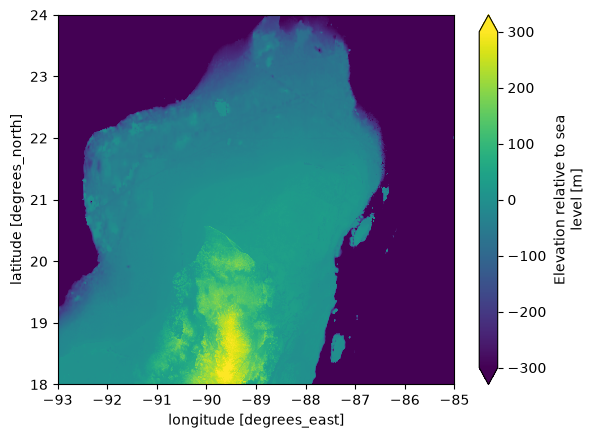

In [19]:
#########################################################       MAPA       ###########################################################
elev.plot(vmin=-300, vmax=300)
plt.show()

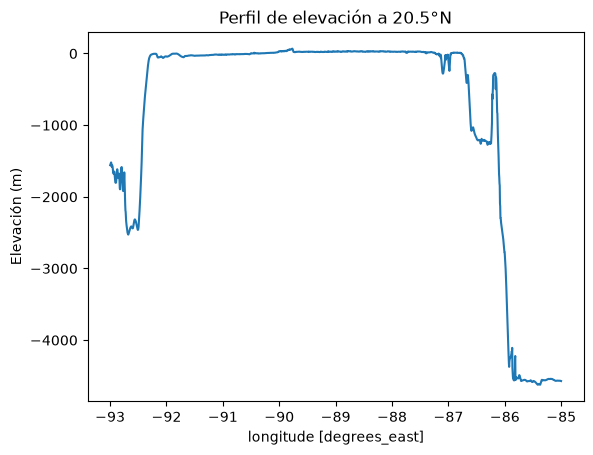

In [20]:
#############################################################      PERFIL     ##################################################################
perfil = datos['elevation'].sel(lat=20.5, method='nearest').sel(lon=slice(-93, -85))
# A)
plt.figure()
perfil.plot()
plt.title("Perfil") # P
plt.ylabel("Elevación (m)")
plt.show()

In [22]:
# B)
tierra = perfil.where(perfil > 0)
alt_max = float(tierra.max())
lon_alt_max = float(tierra.idxmax(dim='lon'))
print(f"Altura máxima en tierra: {alt_max:.1f}")


Altura máxima en tierra: 67.0


In [25]:
# C)

golfo  = perfil.sel(lon=slice(-93, lon_alt_max))
caribe = perfil.sel(lon=slice(lon_alt_max, -85))

print(f"Golfo:  {abs(float(golfo.min())):.1f} m ")
print(f"Caribe: {abs(float(caribe.min())):.1f} m ")

Golfo:  2527.0 m 
Caribe: 4622.0 m 


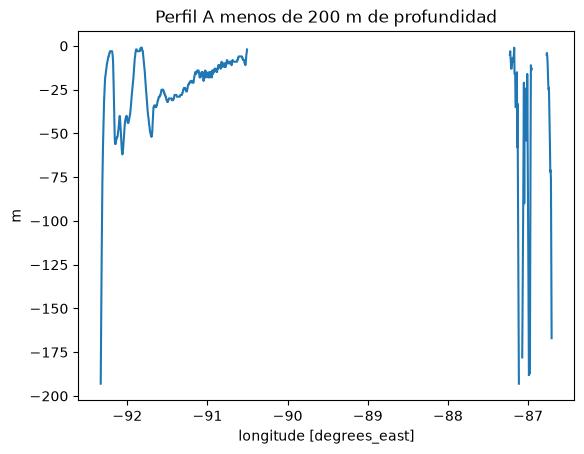

In [26]:
# D) aprox. de -90.5 a -87.5

plataforma = perfil.where((perfil < 0) & (perfil > -200))

plataforma.plot()
plt.title("Perfil A menos de 200 m de profundidad")
plt.ylabel("m")
plt.show()

In [28]:
# E) cual es el lado de la península más ancha?:

signo = np.sign(perfil.values)
idx = np.where(np.diff(signo) != 0)[0]
print("Cambios tierra/mar en lon ≈", perfil.lon.values[idx])

# --- Ancho de la plataforma en cada lado ---
dlon = float(perfil.lon[1] - perfil.lon[0])
km_por_punto = dlon * 111.32 * np.cos(np.radians(20.5))   # 1° de lon a esta latitud

ancho_golfo  = int(plataforma.sel(lon=slice(-93, lon_alt_max)).count()) * km_por_punto
ancho_caribe = int(plataforma.sel(lon=slice(lon_alt_max, -85)).count()) * km_por_punto
print(f"Plataforma lado Golfo:   {ancho_golfo:.0f} km")
print(f"Plataforma lado Caribe:  {ancho_caribe:.0f} km")

# La mas ancha es la del Golfo

Cambios tierra/mar en lon ≈ [-90.50625    -90.47708333 -90.47291667 -90.36875    -90.35625
 -87.23125    -86.95625    -86.77291667]
Plataforma lado Golfo:   191 km
Plataforma lado Caribe:  31 km
